# Ejercicio 01 · Deserción estudiantil con SVM reproducible

**Autora:** Kimberly Pereyra · INF-8239 Ciencia de Datos II

- **Pregunta:** ¿Es posible identificar, al final del 1er semestre, qué estudiantes abandonarán la carrera, seguirán matriculados o se graduarán?
- **Unidad de análisis:** un estudiante de pregrado (una fila = un estudiante).
- **Target:** `Target` (Dropout, Enrolled, Graduate).
- **Fuente:** UCI ML Repository, id 697 — Realinho, V. et al. (2021). DOI 10.24432/C5MC89.
- **Licencia:** CC BY 4.0.
- **Métrica principal:** F1 macro (las tres clases pesan igual); se vigila el recall de `Dropout`.

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from inf8239_u01.data import download_csv, load_data, DEFAULT_PATH

if not DEFAULT_PATH.exists():
    download_csv()
df = load_data()
print(df.shape)

(4424, 37)


In [2]:
audit = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "porcentaje_ausente": (df.isna().mean() * 100).round(2),
    "unicos": df.nunique(dropna=False)
}).sort_values("unicos")
print("Duplicados:", df.duplicated().sum())
print(df["Target"].value_counts(normalize=True).round(3))
display(audit)

Duplicados: 0
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


,tipo,ausentes,porcentaje_ausente,unicos
Daytime/evening attendance,int64,0,0.0,2
Displaced,int64,0,0.0,2
Debtor,int64,0,0.0,2
Educational special needs,int64,0,0.0,2
International,int64,0,0.0,2
Scholarship holder,int64,0,0.0,2
Gender,int64,0,0.0,2
Tuition fees up to date,int64,0,0.0,2
Target,str,0,0.0,3
Marital status,int64,0,0.0,6


**Auditoría**
- 4,424 filas × 37 columnas; 0 duplicados y 0 valores ausentes.
- Balance del target: Graduate 49.9 %, Dropout 32.1 %, Enrolled 17.9 %. Desbalance moderado → F1 macro y partición estratificada.
- Todas las columnas son numéricas en el CSV, pero 9 son **códigos de categoría** (estado civil, modo de ingreso, carrera, calificación previa, nacionalidad, estudios y ocupación de padre y madre). Se tratarán como categóricas con OneHotEncoder, no como cantidades.
- No se elimina ninguna fila.

In [3]:
TARGET = "Target"
DROP_COLUMNS = [c for c in df.columns if "2nd sem" in c]

assert TARGET in df.columns
X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]

print("Retiradas por fuga temporal:", DROP_COLUMNS)
print(X.shape)
print(y.value_counts(dropna=False))
assert y.notna().all()
assert y.nunique() >= 2

Retiradas por fuga temporal: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
(4424, 30)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


**Prevención de fuga**
La decisión se toma **al final del 1er semestre**. Las 6 variables `Curricular units 2nd sem (...)` todavía no existen en ese momento, por lo que usarlas daría al modelo información del futuro. Se excluyen por **disponibilidad temporal**, no por su efecto en la métrica.
No hay identificadores de estudiante en el dataset, así que no se retira ninguna columna de ID.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
assert set(cat_cols) <= set(X.columns), set(cat_cols) - set(X.columns)
num_cols = [c for c in X.columns if c not in cat_cols]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocess = ColumnTransformer([("num", num_pipe, num_cols),
                                ("cat", cat_pipe, cat_cols)])
print(len(num_cols), "numéricas |", len(cat_cols), "categóricas")

21 numéricas | 9 categóricas


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, f1_score

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(Xtr.shape, Xte.shape)

dummy = Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="most_frequent"))])
svm = Pipeline([("prep", preprocess), ("model", SVC(C=1, gamma="scale", probability=True, random_state=42))])

for name, model in {"dummy": dummy, "svm": svm}.items():
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(name, "F1 macro:", round(f1_score(yte, pred, average="macro"), 4))

(3539, 30) (885, 30)
dummy F1 macro: 0.2221


c:\Users\kpereyra\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


svm F1 macro: 0.6321


              precision    recall  f1-score   support

     Dropout     0.7918    0.6831    0.7335       284
    Enrolled     0.4565    0.2642    0.3347       159
    Graduate     0.7482    0.9276    0.8283       442

    accuracy                         0.7299       885
   macro avg     0.6655    0.6250    0.6321       885
weighted avg     0.7098    0.7299    0.7092       885



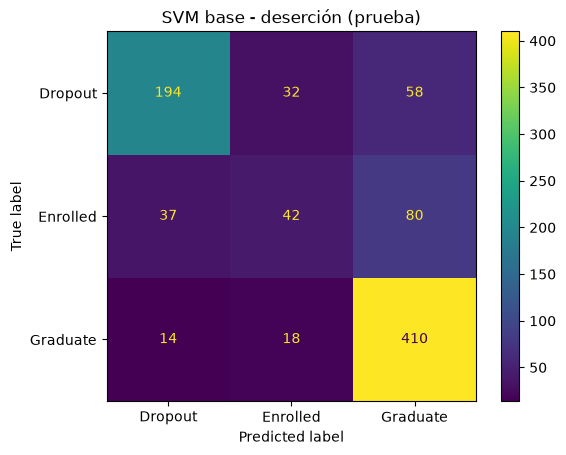

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
labels = ["Dropout", "Enrolled", "Graduate"]

svm_pred = svm.predict(Xte)
print(classification_report(yte, svm_pred, labels=labels, digits=4))

ConfusionMatrixDisplay.from_predictions(yte, svm_pred, labels=labels)
plt.title("SVM base - deserción (prueba)")
plt.savefig(REPORTS / "desercion_svm_base_cm.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretación de la SVM base**

- F1 macro: **0.632** frente a 0.222 del baseline (Dummy que siempre predice Graduate). Accuracy 0.730.
- **Graduate** se reconoce bien (recall 0.93) y **Dropout** de forma aceptable (recall 0.68).
- **Enrolled** es la clase más difícil (recall 0.26): solo 42 de 159 se identifican; 80 se confunden con Graduate. Es la clase minoritaria (18 %) y, a mitad de carrera, su perfil se parece al de quienes se gradúan.
- **Error más costoso:** 58 estudiantes que abandonaron fueron clasificados como Graduate. Son casos que no recibirían tutoría a tiempo. Otros 32 Dropout se clasificaron como Enrolled.
- Como el modelo favorece a la clase mayoritaria, en la búsqueda de hiperparámetros se prueba también `class_weight="balanced"`, que da más peso a las clases minoritarias.

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    estimator=svm,
    param_grid={
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__class_weight": [None, "balanced"],
    },
    scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True,
)
search.fit(Xtr, ytr)
print(search.best_params_)
print("CV F1 macro:", round(search.best_score_, 4))

c:\Users\kpereyra\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


{'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
CV F1 macro: 0.6869


In [8]:
cv_results = pd.DataFrame(search.cv_results_)
columns = ["param_model__C", "param_model__gamma", "param_model__class_weight",
           "mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]
cv_table = cv_results[columns].sort_values("mean_test_score", ascending=False)
cv_table.head(10)

,param_model__C,param_model__gamma,param_model__class_weight,mean_test_score,std_test_score,mean_train_score,mean_fit_time
16,10.0,0.01,balanced,0.686897,0.017805,0.839031,18.629900
9,1.0,scale,balanced,0.681339,0.018182,0.812754,24.368970
13,10.0,0.01,NaN,0.670896,0.026084,0.823464,18.431140
11,1.0,0.1,balanced,0.666122,0.019608,0.940138,32.284610
15,10.0,scale,balanced,0.664987,0.019619,0.973327,26.317607
10,1.0,0.01,balanced,0.658496,0.017097,0.705133,25.549591
12,10.0,scale,NaN,0.657613,0.023691,0.970836,23.995752
6,1.0,scale,NaN,0.645069,0.014310,0.772287,21.400177
17,10.0,0.1,balanced,0.642219,0.019138,1.000000,20.767414
14,10.0,0.1,NaN,0.641448,0.018701,1.000000,36.909728


**Interpretación de GridSearchCV (5 folds estratificados, solo entrenamiento, 18 configuraciones)**

- Mejor configuración: **C = 10, gamma = 0.01, class_weight = balanced** → F1 macro CV = 0.687 ± 0.018.
- `class_weight="balanced"` aparece en 5 de las 6 mejores configuraciones: dar más peso a las clases minoritarias (Enrolled, Dropout) mejora el F1 macro.
- Las dos mejores (0.687 y 0.681) están dentro de una desviación estándar, así que la diferencia entre ellas **no es concluyente**.
- **Sobreajuste:** con gamma = 0.1 o gamma = "scale" y C = 10, el F1 en entrenamiento llega a 0.94–0.97 mientras el de validación baja a ≈ 0.665. La configuración elegida tiene una brecha menor (0.839 vs 0.687).
- El conjunto de prueba no se usó para elegir hiperparámetros; se evalúa una sola vez a continuación.

              precision    recall  f1-score   support

     Dropout     0.7975    0.6655    0.7255       284
    Enrolled     0.3982    0.5660    0.4675       159
    Graduate     0.8294    0.7919    0.8102       442

    accuracy                         0.7107       885
   macro avg     0.6750    0.6745    0.6677       885
weighted avg     0.7417    0.7107    0.7215       885



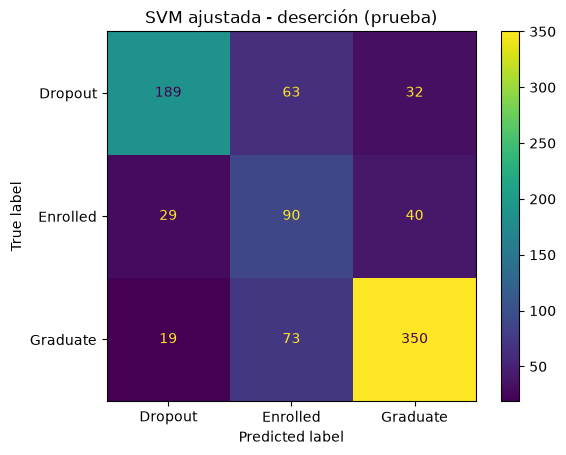

In [9]:
from sklearn.metrics import recall_score

best = search.best_estimator_
best_pred = best.predict(Xte)
print(classification_report(yte, best_pred, labels=labels, digits=4))

ConfusionMatrixDisplay.from_predictions(yte, best_pred, labels=labels)
plt.title("SVM ajustada - deserción (prueba)")
plt.savefig(REPORTS / "desercion_svm_best_cm.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
import joblib

summary = pd.DataFrame([
    {"modelo": "Dummy (most_frequent)", "f1_macro": f1_score(yte, dummy.predict(Xte), average="macro"),
     "recall_dropout": recall_score(yte, dummy.predict(Xte), labels=["Dropout"], average="macro")},
    {"modelo": "SVM base (C=1, gamma=scale)", "f1_macro": f1_score(yte, svm_pred, average="macro"),
     "recall_dropout": recall_score(yte, svm_pred, labels=["Dropout"], average="macro")},
    {"modelo": "SVM ajustada (C=10, gamma=0.01, balanced)", "f1_macro": f1_score(yte, best_pred, average="macro"),
     "recall_dropout": recall_score(yte, best_pred, labels=["Dropout"], average="macro")},
]).round(4)

summary.to_csv(REPORTS / "desercion_resultados.csv", index=False)
cv_table.to_csv(REPORTS / "desercion_svm_cv_results.csv", index=False)
joblib.dump(best, REPORTS / "desercion_svm_best.joblib")
summary

,modelo,f1_macro,recall_dropout
0,Dummy (most_frequent),0.2221,0.0000
1,"SVM base (C=1, gamma=scale)",0.6321,0.6831
2,"SVM ajustada (C=10, gamma=0.01, balanced)",0.6677,0.6655
